In [1]:
import argparse

from pathlib import Path

# from src.make_folders import make_folders
from src.dataset import CBCTDataset 
from src.dataprep import save_pickle
from helper_functions.helpers import load_config
from helper_functions.training_loggers import plot_loss
from exec_scripts.pretrain import pretrain
from preprocess.make_data import preprocess
from src.model_utils import embed_databank

C:\Users\33644\Documents\Theses\venv314\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
from pathlib import Path
from tqdm import tqdm
from torch.utils.data import DataLoader

from helper_functions.helpers import (get_gpu_usage, load_config, save_checkpoint, set_seed, move_batch_to_device, summarize_model)
from src.model.lpjepa import LpJEPA

In [3]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as Funct

# personnal
import libraries
import libraries.data_loader as dl

In [4]:
path = r"datas/mnist.npz"
(X_train, Y_train), (X_val, Y_val) = dl.load_datas(path)
X_train = X_train.reshape((60000, 1, 28, 28))
X_val = X_val[:].reshape((10000, 1, 28, 28))



X_train.shape, X_val.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

In [5]:
def load_config(config_path: Path):
    with open(config_path, "r") as f:
        config = json.load(f)

    return config

path = r"config/config.json"
config = load_config(path)

In [6]:
set_seed(config.get("seed"))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X = X_train
# X = np.pad(X, (2,2), "constant", constant_values=(0,0))
X = X[:, :, 2:26, 2:26].astype(np.float32)/255


X = torch.from_numpy(X)
X.shape

torch.Size([60000, 1, 24, 24])

In [7]:
data_type: str
epochs: int = 50
batch_size: int = 500
patch_size: int = 6
num_workers: int = 1

img_size = 24
num_views = 5
num_projs = 20

d_model = 48
num_heads = 6

num_encoder_layers = 6
use_class: bool = True

dataloader = DataLoader(X, batch_size=batch_size, shuffle=True, num_workers=num_workers, drop_last=True,
                            persistent_workers=True, pin_memory=True)


In [3]:
jepa = LpJEPA(
        # Encoder part
        image_size=img_size,
        d_model=d_model,
        patch_size=patch_size,
        num_heads=num_heads,
        num_encoder_layers=num_encoder_layers,
        mlp_ratio=int(config.get("encoder")["mlp_ratio"]),
        mlp_drop=config.get("encoder")["mlp_drop"],
        drop_path_rate=config.get("encoder")["drop_path_rate"],
        num_views=num_views,
    
        # Projector part
        proj_dim=d_model,
        mu=-0.5,
        sigma=1,
        p=2,
        num_projs=num_projs,
    
        # Loss part
        lambda_inv=0.2,
        rdm= True,
        knots=config.get("rdm_reg")["knots"]
    ).to(device)

NameError: name 'img_size' is not defined

In [12]:
from helper_functions.schedulers import WarmupCosineSchedule
from helper_functions.training_loggers import MetricTracker, CsvLogger, GradientLogger

optimizer=torch.optim.AdamW(params=jepa.parameters(), lr=config["training"]["start_lr"])
warmup_steps = len(dataloader) * int(epochs * config["training"]["warmup_ratio"])
total_steps = len(dataloader) * epochs
scheduler = WarmupCosineSchedule(
    optimizer=optimizer,
    warmup_steps=warmup_steps,
    T_max=total_steps,
    start_lr=config["training"].get("start_lr"),
    ref_lr=config["training"].get("ref_lr"),
    final_lr=config["training"].get("final_lr")
)

In [15]:
epochs = 10

metrics_list = ["loss", "inv", "rdm", "sparse_prop"]
if use_class:
    metrics_list.insert(3, "class")
metrics_tracker = MetricTracker(*metrics_list)

grad_logger = GradientLogger(jepa)

csv_headers = ["Epoch", "Loss", "MSE", "RDMReg", "Sparsity"]
if use_class:
    csv_headers.insert(4, "Class")
csv_loss_logger = CsvLogger(
    file_path=Path("logs"),
    csv_name="losses.csv",
    headers=["Epoch", "Loss", "MSE", "RDMReg", "Sparsity"]
)
csv_grad_logger = CsvLogger(
    file_path=Path("logs"),
    csv_name="gradients.csv",
    headers=["Epoch", "Batch", "gradient_norm"]
)

checkpoint_dir = Path("checkpoints")
checkpoint_freq = config["logging"].get("checkpoint_freq")

best_model_score = -np.inf

for epoch in range(epochs):
    progress_bar = tqdm(dataloader, leave=True, ncols=50, dynamic_ncols=True, desc=f"Epoch {epoch+1}/{epochs}")
    for b, batch in enumerate(progress_bar):
        optimizer.zero_grad()
        # data, _ = batch
        tensor = batch
        if not use_class:
            is_ct = None
        results = jepa(tensor)

        metrics_dict = dict(zip(metrics_list, results))
        metrics_tracker.update_all(metrics_dict, batch_size)
        results[0].backward()
        grad_norm = grad_logger.log_gradients()
        csv_grad_logger.log([epoch+1, b+1, grad_norm])

        optimizer.step()
        scheduler.step()

        postfix_stats = metrics_tracker.result()
        postfix_stats["lr"] = optimizer.param_groups[0]["lr"]
        postfix_stats["grad"] = grad_norm
        if device.type == "cuda":
            postfix_stats.update(get_gpu_usage())
        progress_bar.set_postfix(postfix_stats)

    # if (epoch+1) % checkpoint_freq == 0:
    #     checkpoint_path = checkpoint_dir / f"checkpoint_{epoch+1}.pth"
    #     save_checkpoint(jepa, optimizer, scheduler, checkpoint_path)

    csv_loss_logger.log([epoch+1, *metrics_tracker.result().values()])

    # model_quality_score = score_model(metrics_tracker.result(), lambda_inv=config.get("loss")["lambda_inv"])

    # if model_quality_score > best_model_score:
    #     best_model_score = model_quality_score
    #     print(f'Current best model score: {best_model_score:.4f}')
    #     save_path = Path(model_path)
    #     torch.save(jepa, save_path)

Epoch 1/10: 100%|█| 120/120 [05:47<00:00,  2.90s/it, loss=0.01, inv=0.0434, rdm=0.0017, class=22.2, sparse_prop=0, lr=0
Epoch 2/10: 100%|█| 120/120 [05:44<00:00,  2.87s/it, loss=0.00999, inv=0.0432, rdm=0.00169, class=21.1, sparse_prop=0, 
Epoch 3/10: 100%|█| 120/120 [05:45<00:00,  2.88s/it, loss=0.00997, inv=0.0431, rdm=0.00169, class=20.5, sparse_prop=0, 
Epoch 4/10: 100%|█| 120/120 [05:45<00:00,  2.88s/it, loss=0.0099, inv=0.0429, rdm=0.00165, class=19.6, sparse_prop=0, l
Epoch 5/10: 100%|█| 120/120 [05:45<00:00,  2.88s/it, loss=0.00984, inv=0.0427, rdm=0.00161, class=18.7, sparse_prop=0, 
Epoch 6/10: 100%|█| 120/120 [05:46<00:00,  2.89s/it, loss=0.00978, inv=0.0426, rdm=0.00158, class=17.8, sparse_prop=0, 
Epoch 7/10: 100%|█| 120/120 [06:01<00:00,  3.01s/it, loss=0.00974, inv=0.0425, rdm=0.00156, class=17, sparse_prop=0, lr
Epoch 8/10: 100%|█| 120/120 [06:11<00:00,  3.09s/it, loss=0.0097, inv=0.0424, rdm=0.00154, class=16.4, sparse_prop=0, l
Epoch 9/10: 100%|█| 120/120 [05:52<00:00

# See views

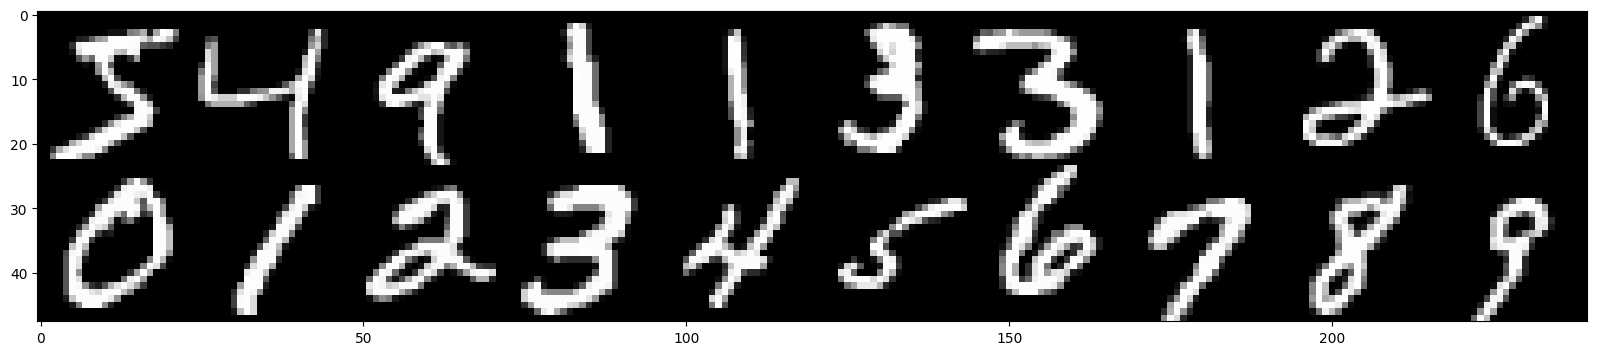

In [16]:
index = 20
X_train = X.detach().numpy()
images = np.array(X_train[:index].mean(axis = 1), dtype = np.float32) /256
# images = exp_softmax(images)

cols = 10
new_images = images.reshape((cols, index//cols,) + X_train.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images, cmap = 'gray')

In [81]:
V = 10

x = X[:5]

x = x.repeat(V, 1, 1, 1)
x, crop_coords, attn_mask = jepa.gpu_augmentation(x)
x.shape

torch.Size([50, 1, 24, 24])

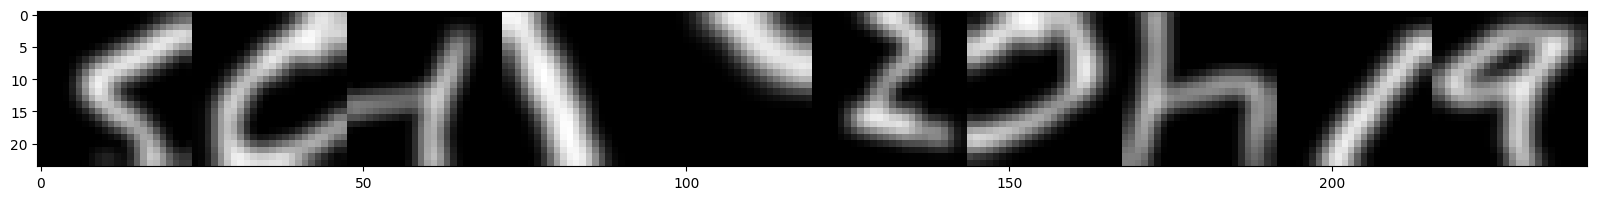

In [82]:
index = 10
X_train = x.detach().numpy()
images = np.array(X_train[:10].mean(axis = 1), dtype = np.float32) /256
# images = exp_softmax(images)

cols = 10
new_images = images.reshape((cols, index//cols,) + X_train.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images, cmap = 'gray')

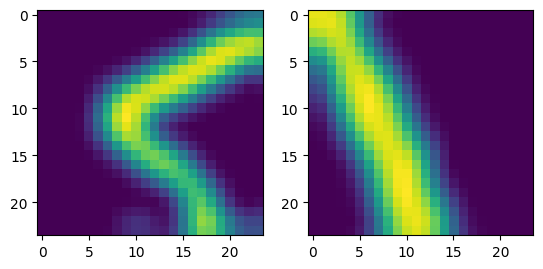

In [87]:
x2 = x.reshape((5, 10, 24, 24))

fig, ax = plt.subplots(1, 2)
ax[0].imshow(x[0, 0])
ax[1].imshow(x[3, 0])

In [99]:
jepa.training = False
jepa.training 

False

In [68]:
X.shape, X.max()

(torch.Size([60000, 1, 24, 24]), tensor(1.))

In [97]:
length = 10
x = X[:length]
tokens = jepa.patch_embedder(x)
crop_coords = torch.tensor([[0., 24., 0., 24.]]*10)
encoded_seq = jepa.encoder(tokens, crop_coords=crop_coords, attn_mask=attn_mask)

RuntimeError: The size of tensor a (10) must match the size of tensor b (50) at non-singleton dimension 0

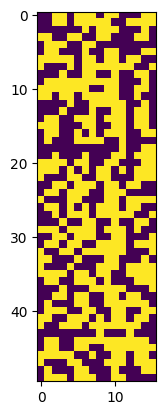

In [94]:
plt.imshow(attn_mask.detach().numpy())
mask_expanded = attn_mask.unsqueeze(-1)

In [95]:
torch.clamp(mask_expanded.sum(dim=1), min=1.0).shape

torch.Size([50, 1])

In [19]:
results = jepa(tensor)

In [20]:
# loss, inv_loss, dist_loss, sparsity
results

(tensor(0.0095, grad_fn=<AddBackward0>),
 tensor(0.0415, grad_fn=<MseLossBackward0>),
 tensor(0.0015, grad_fn=<MseLossBackward0>),
 10.352499783039093)

# See latent

In [21]:
z, z_proj = jepa.embed_tokens(tensor)
z_mean = z.mean(dim=1, keepdim=True)

In [22]:
z.shape, z_proj.shape, z_mean.shape

(torch.Size([500, 5, 48]), torch.Size([2500, 48]), torch.Size([500, 1, 48]))

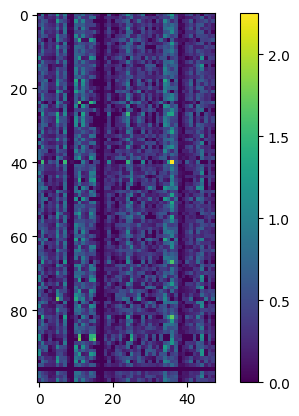

In [27]:
plt.imshow(z_proj[:100].detach().numpy())
plt.colorbar()

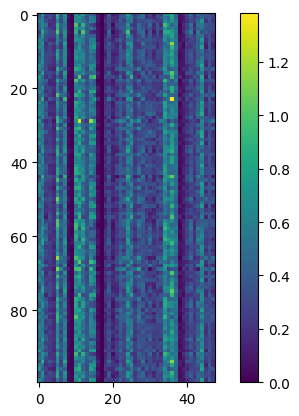

In [31]:
plt.imshow(z_mean[:100, 0].detach().numpy())
plt.colorbar()

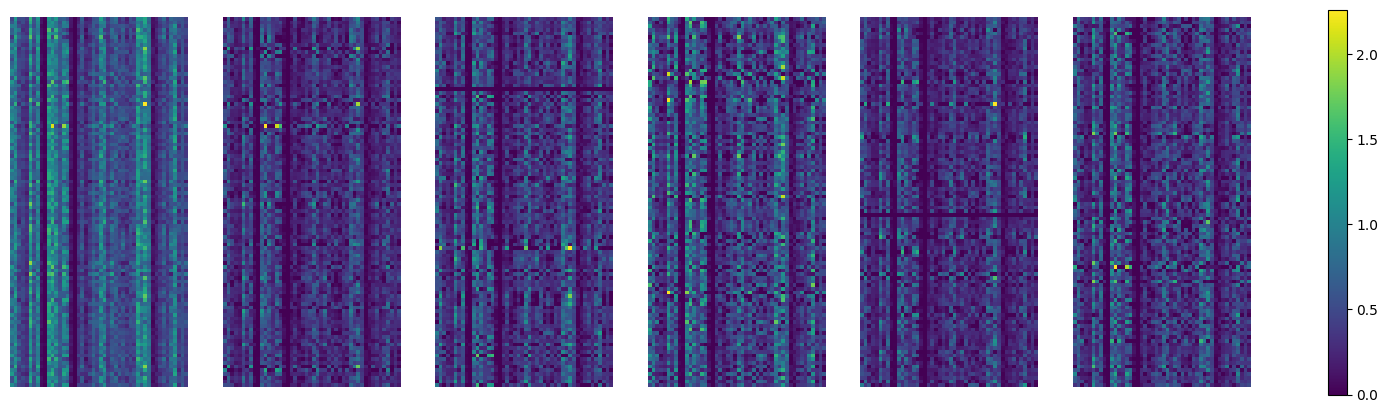

In [62]:
fig, ax = plt.subplots(1, jepa.num_views +1, figsize = (20,10))

ax[0].set_axis_off()
ax[0].imshow(z_mean[:100, 0].detach().numpy())
for i in range(jepa.num_views) :
    ax[i+1].set_axis_off()
    pcm = ax[i+1].imshow(z[:100, i].detach().numpy())
    # plt.colorbar()
fig.colorbar(pcm, ax = ax, shrink = 0.5)
plt.show()

In [24]:
parsity = (z_proj == 0).float().mean().item() * 100
sparsity

11.420000344514847

In [ ]:
latent_global = []
batchsize = 200
batch_range_train = range(0, X_train.shape[0] +1, batchsize)
for i, batch in batch_range_train : 
    

# Predicter

In [65]:
class Predictor(nn.Module) : 
    def __init__(self, input_dim) :
        super().__init__()
        
        self.linear = nn.Sequential(
            nn.Linear(input_dim, 20),
            nn.ReLU(),
            nn.Linear(20, 10),
            nn.Sigmoid()
        )

    def forward(self, z) :
        return self.linear(z)
        

In [67]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
predicter = Predictor(40).to(device)

In [ ]:
from IPython.display import clear_output
epochs = 50
batch_size = 250

torch.manual_seed(42)
# batch_range_train = range(0, X_train.shape[0] +1, batchsize)
dataloader = DataLoader(latent_global, batch_size=batch_size, shuffle=False)

optimizer=torch.optim.AdamW(params=predicter.parameters(), lr=5e-3)

for epoch in range(epochs):
    
    progress_bar = tqdm(dataloader, leave=True, ncols=50, dynamic_ncols=True, desc=f"Epoch {epoch+1}/{epochs}")
    for b, batch in enumerate(progress_bar):
        clear_output(wait=True)
        
        optimizer.zero_grad()
        # batch = torch.from_numpy(batch)
        batch = batch.to(device)

        real = F.one_hot(torch.from_numpy(Y_train[b*batch_size:(b+1)*batch_size]).type(torch.LongTensor), num_classes = -1)
        
        results = predicter(batch)

        loss = F.binary_cross_entropy(results, real.type(torch.float32))
        
        loss.backward()

        optimizer.step()

        print(f'{b} - {loss.item()}')

        

In [ ]:
# Reconstruction

In [40]:
def TCNN_28x28(F, FILTER) :
    CNN_Transpose = nn.Sequential(
            nn.ConvTranspose2d(FILTER *8, FILTER *4, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(FILTER *4, FILTER *2, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(FILTER *2, FILTER, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(FILTER, F, kernel_size=3, stride=1, padding=1),
    )
    return CNN_Transpose
    
class Decoder(nn.Module):
    def __init__(self, D, F, FILTER):
        super(Decoder, self).__init__()
        self.F = F
        self.D = D # latent shape [N x D]

        self.Linear = nn.Linear(in_features = D, out_features = FILTER * 8 * 16)
        
        # TCNN (CNN Transpose)
        self.TCNN = TCNN_28x28(F, FILTER)
        self.Sigmoid = nn.Sigmoid()
        
    def forward(self, Z):
        Z = self.Linear(Z)
        Z = Z.view(-1, Z.shape[-1]//16, 4, 4)
        
        hat_X = self.TCNN(Z)
        hat_X = self.Sigmoid(hat_X) # sigmoid nécessaire pour BCE_loss
        return hat_X

In [41]:
D = 48
F = 1
FILTER = 25

net = Decoder(D, F, FILTER)


In [ ]:
cur_epoch = 1
epochs, batchsize  = 50, 1000
alpha = 0.25
beta = 0.5
gamma = 5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
learning_rate = 1e-3

torch.manual_seed(42)
optimizer = torch.optim.Adam(params=net.parameters(), lr=learning_rate, weight_decay=1e-5)

BCE = Funct.binary_cross_entropy

# batch_range_train = range(0, X_train.shape[0] +1, batchsize)
dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(M))
dataloader = DataLoader(dataset, batch_size=batchsize, shuffle=True)
ratio = 100 /batchsize /np.prod(X_train.shape[1:]) # Avoir une erreur relative à la dimension des données et de la taille du batch

# Passe le modèle en mode "apprentissage"
net = net.to(device)
net = net.train()


print(f"{cur_epoch}/{epochs}, Entraînement du modèle")

AVG_loss = []
begin = time.time()
for epoch in range(cur_epoch, epochs +1):
    print(f"epoch {epoch}/{epochs}")
    avg_loss = []
    
    # Parcours du dataset pour une epoch
    RT_X = get_RT_X(X_train[:1], M[:1])
    display_epoch(net, torch.from_numpy(RT_X))
    for i, (S, D) in enumerate(dataloader) :

        # X = get_RT_X(X_train[batch:batch_range_train[i +1]], M[batch:batch_range_train[i +1]])
        X = get_RT_X(S.detach().numpy(), D.detach().numpy())
        X = torch.from_numpy(X)
        X = X.to(device)
        
        # Calcul de l'erreur
        loss, loss_STRUCT, loss_DOSE, loss_KLD, loss_TC = net(X, alpha = alpha, beta = beta, gamma = gamma) # X, beta = 1. # 9 *epoch/epochs +1

        # Rétropropagation du gradient
        optimizer.zero_grad()
        loss.backward()
        # Descente de gradient (une itération)
        optimizer.step()
        

        loss_ratio = loss.item() *ratio
        loss_STRUCT, loss_DOSE, loss_KLD, loss_TC = np.array([loss_STRUCT, loss_DOSE, loss_KLD, loss_TC]) *ratio
        print(f"{epoch} {i +1}", np.round(loss_ratio, 4), np.round(loss_STRUCT, 4), np.round(loss_DOSE, 4), np.round(loss_KLD, 4), np.round(loss_TC, 4))
        avg_loss.append([loss_ratio, loss_STRUCT, loss_DOSE, loss_KLD, loss_TC])
        
    AVG_loss.append(avg_loss)
    clear_output()
end = time.time()